In [1]:
import os
import sys
from pathlib import Path

# Xác định thư mục gốc của project
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    BASE_DIR = CURRENT_DIR.parent
elif (CURRENT_DIR / "src").exists():
    BASE_DIR = CURRENT_DIR
elif (CURRENT_DIR.parent / "src").exists():
    BASE_DIR = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Không tìm thấy thư mục gốc project chứa src/. "
        f"Thư mục hiện tại: {CURRENT_DIR}"
    )

# Đưa thư mục gốc vào Python path
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

# Chuyển working directory về thư mục gốc
os.chdir(BASE_DIR)

print(f"Thư mục làm việc: {BASE_DIR}")


Thư mục làm việc: d:\GitHub\ML-Kaggle-Project\cafe-revenue-regression


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.style.use('ggplot')
pd.set_option('display.max_columns', None)


In [6]:
# Gọi các pipeline từ src/data/ đã viết
from src.data.load import load_raw_data
from src.data.validate import run_validation_pipeline
from src.data.join import build_feature_ready_data

raw_data = load_raw_data()
clean_data = run_validation_pipeline(raw_data)
train_df, test_df = build_feature_ready_data(clean_data)

# Chọn các đặc trưng số học cơ bản cho ML truyền thống
features = [ 'is_promo', 'area_m2', 'seats', 'has_parking', 'temp_c', 'rain_mm', 'is_holiday' ]
target = 'revenue'

X = train_df[features].fillna(0)
y = train_df[target]
y_log = np.log1p(y)

2026-10-25 16:38:44,566 - INFO - Starting Data Validation Pipeline...
2026-10-25 16:38:44,572 - INFO - Deduplication: Removed 132 duplicate rows from train data.
2026-10-25 16:38:44,587 - INFO - Missing-value handling completed. Weather shape: (1593, 4); stores shape: (45, 8)
2026-10-25 16:38:44,588 - INFO - Data Validation Pipeline Completed Successfully.
2026-10-25 16:38:44,646 - INFO - Join successful: 26500 rows, 15 columns
2026-10-25 16:38:44,648 - WARNING - sample_sub chỉ có id và revenue. Cần xác định quy tắc id trước khi tạo test data.


train        -> Shape: (26632, 4)
stores       -> Shape: (45, 8)
weather      -> Shape: (1593, 4)
holidays     -> Shape: (55, 3)
sample_sub   -> Shape: (3869, 2)


In [7]:
# Định nghĩa hàm tính RMSLE chuẩn
def rmsle(y_true, y_pred):
    y_pred_clipped = np.clip(y_pred, 0, None)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred_clipped)))

results = {}

# 1. Baseline Median
from src.models.baseline import NaiveStoreWeekdayMedianBaseline
base_model = NaiveStoreWeekdayMedianBaseline().fit(train_df)
base_preds = base_model.predict(train_df)
results['Naive Baseline (Median)'] = rmsle(y, base_preds)

# 2. Các mô hình ML Truyền Thống (Huấn luyện trên log1p)
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, random_state=42)
}

for name, model in models.items():
    model.fit(X, y_log)
    preds_log = model.predict(X)
    preds = np.expm1(preds_log) # Biến đổi ngược
    results[name] = rmsle(y, preds)

# Chuyển kết quả thành DataFrame để so sánh
df_results = pd.DataFrame(list(results.items()), columns=['Model', 'Train RMSLE'])
df_results.sort_values(by='Train RMSLE', ascending=True)

,Model,Train RMSLE
0,Naive Baseline (Median),0.351274
4,Decision Tree,0.375833
1,Linear Regression,0.469924
2,Ridge Regression,0.469924
3,Lasso Regression,0.480087


C:\Users\Vu Thu Hang\AppData\Local\Temp\ipykernel_30640\2459533537.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x='Train RMSLE', y='Model', palette='viridis')


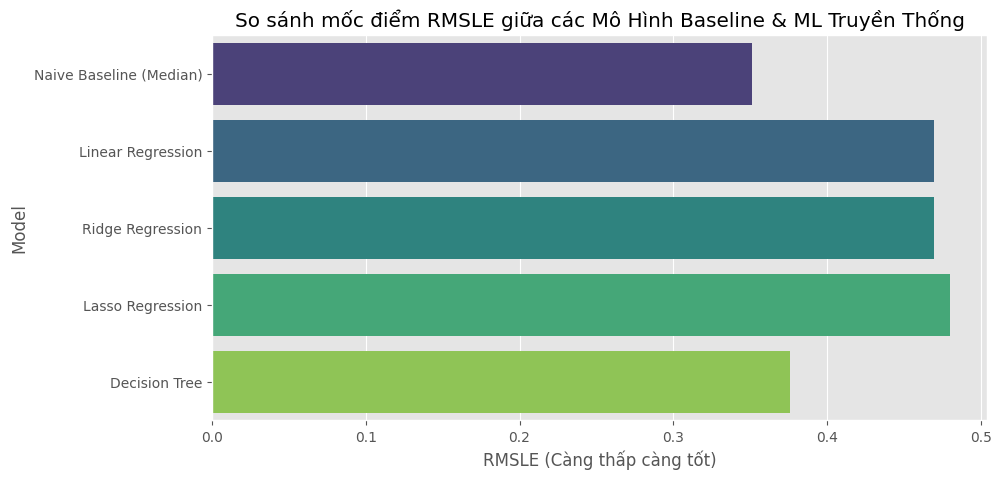

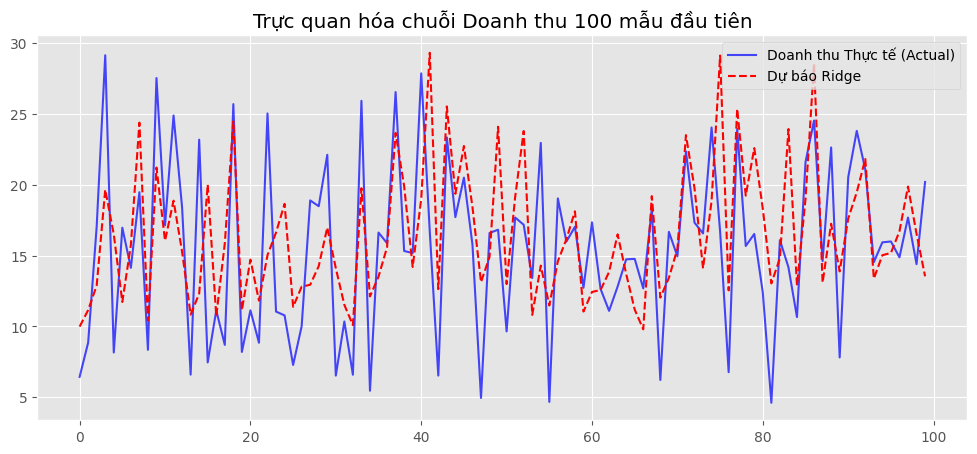

In [8]:
# Biểu đồ so sánh điểm RMSLE giữa các mô hình
plt.figure(figsize=(10, 5))
sns.barplot(data=df_results, x='Train RMSLE', y='Model', palette='viridis')
plt.title('So sánh mốc điểm RMSLE giữa các Mô Hình Baseline & ML Truyền Thống')
plt.xlabel('RMSLE (Càng thấp càng tốt)')
plt.show()

# Biểu đồ so sánh Doanh thu Thực tế vs Dự báo của mô hình tốt nhất
plt.figure(figsize=(12, 5))
plt.plot(y.values[:100], label='Doanh thu Thực tế (Actual)', color='blue', alpha=0.7)
plt.plot(np.expm1(models['Ridge Regression'].predict(X[:100])), label='Dự báo Ridge', color='red', linestyle='--')
plt.title('Trực quan hóa chuỗi Doanh thu 100 mẫu đầu tiên')
plt.legend()
plt.show()